In [1]:
''''
making sat traini`bng data
'''

"'\nmaking sat training data\n"

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt



import precision_recall as pr


# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os



import importlib
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [2]:
df_sats = pd.read_csv("/home/3155/satsofar")

In [4]:
len(df_sats)

72

In [19]:
for filename in np.unique(df_sats['filename']):
    df = df_sats[df_sats['filename']==filename]
    for quad in np.unique(df['quad']):
        print(quad)

2
4
2
1
1
4
1
3
3
4


In [7]:
ranges = np.arange(-9,10)

In [6]:
ranges

array([-10,  -9,  -8,  -7,  -6,  -5,  -4,  -3,  -2,  -1,   0,   1,   2,
         3,   4,   5,   6,   7,   8,   9])

In [16]:
row=20
addrow=0
row - 10  + addrow

10

In [17]:
#below here new
fpath_image = "/lustre/lrspec/ZTF_data/2022/1020/"
stampstosave = []
infotosave = []
# bgtosave = []
# bginfo = []

for i in range(len(df_sats)):
    addrow=0
    addcol=0
    fname = df_sats.iloc[i]["filename"]
    image_filename = fname+'fits.fz'
    # filename_start = image_filename[:40]
    image_filename_full = fpath_image + image_filename
    # print(image_filename)
    hdul = fits.open(image_filename_full)
    file1_array = hdul[df_sats.iloc[i]["quad"]].data
    row = int(df_sats.iloc[i]['satcrossing'])
    col = int(df_sats.iloc[i]['streakxposition'])
    for addcol in ranges:
#         if (row - 10  + addrow > 15) & (col  - 10 + addcol > 15):
#             # addrow=0
#             stamp = file1_array[row - 10  + addrow: row + 10 + addrow,
#                             col  - 10 + addcol : col + 10 + addcol ,
#                         ]
#             # plt.imshow(stamp)
#             # plt.show()
#             # stp, bg = ff.get_stamp_from_df(i,  cr_0820, direcname="training_aug24/implant_train/", quad=1, norm=True, addrow=addrow, addcol=addcol, iloc=True) #pretty sure this was iloc before
#             stampstosave.append(stamp)
#             infotosave.append(np.array((df_sats.iloc[i]['filename'], df_sats.iloc[i]['quad'], row, col, addcol, addrow)))
    
        for addrow in ranges:
            if (row - 10  + addrow > 15) & (col  - 10 + addcol > 15) & (row + 10  + addrow < 3065) & (col  + 10 + addcol < 3065):
                # addcol=0
                stamp = file1_array[row - 10  + addrow: row + 10 + addrow,
                                col - 10 + addcol : col  + 10 + addcol ,
                            ]
                # stp, bg = ff.get_stamp_from_df(i,  cr_0820, direcname="training_aug24/implant_train/", quad=1, norm=True, addrow=addrow, addcol=addcol, iloc=True) #pretty sure this was iloc before
                stampstosave.append(stamp)
                infotosave.append(np.array(( df_sats.iloc[i]['filename'], df_sats.iloc[i]['quad'], row, col, addcol, addrow)))
    
# np.save("/lustre/lrspec/ZTF_data/training_feb26/images/cr_0820.npy", stampstosave)
# np.save("/lustre/lrspec/ZTF_data/training_feb26/info/cr_0820_info.npy", infotosave)


In [18]:
len(stampstosave)

25460

In [9]:
len(stampstosave)

25631

In [67]:
len(stampstosave)

1775

In [57]:
len(stampstosave)

710

In [43]:
np.array?

Docstring:
array(object, dtype=None, *, copy=True, order='K', subok=False, ndmin=0,
      like=None)

Create an array.

Parameters
----------
object : array_like
    An array, any object exposing the array interface, an object whose
    ``__array__`` method returns an array, or any (nested) sequence.
    If object is a scalar, a 0-dimensional array containing object is
    returned.
dtype : data-type, optional
    The desired data-type for the array. If not given, NumPy will try to use
    a default ``dtype`` that can represent the values (by applying promotion
    rules when necessary.)
copy : bool, optional
    If true (default), then the object is copied.  Otherwise, a copy will
    only be made if ``__array__`` returns a copy, if obj is a nested
    sequence, or if a copy is needed to satisfy any of the other
    requirements (``dtype``, ``order``, etc.).
order : {'K', 'A', 'C', 'F'}, optional
    Specify the memory layout of the array. If object is not an array, the
    newly crea

In [71]:
infotosave[95]

array(['ztf_20221020148032_000686_zg_c03_x_0011.', '4', '1552', '2238',
       '2', '-2'], dtype='<U40')

In [48]:
thing.shape

(14360, 20)

In [12]:
stampstosave

[array([[164.70729, 166.37799, 167.1739 , 160.18048, 168.19345, 167.39978,
         163.85591, 168.00774, 169.20395, 168.38571, 157.21748, 161.45157,
         168.97864, 167.17932, 177.0873 , 177.61436, 181.02736, 219.80867,
         286.58734, 310.8356 ],
        [167.68994, 167.92435, 165.76782, 164.93517, 164.83253, 160.97215,
         165.15701, 166.76779, 166.54788, 161.96371, 157.2787 , 164.18385,
         172.7589 , 170.05835, 175.75   , 173.80228, 188.66786, 232.40625,
         299.62375, 297.6157 ],
        [174.20816, 163.44057, 166.13475, 162.3625 , 159.79218, 156.0552 ,
         161.73396, 166.42363, 155.84744, 164.86086, 164.24031, 162.60196,
         161.56883, 165.49115, 181.52034, 171.54358, 182.71649, 246.37009,
         304.8164 , 311.3255 ],
        [165.8225 , 167.97913, 162.44379, 165.58986, 166.42372, 162.87648,
         163.98715, 167.5586 , 163.8053 , 167.06165, 165.6513 , 160.9842 ,
         161.55357, 167.67587, 173.99982, 181.05478, 185.05426, 241.31766,
    

In [19]:
stampstosave = np.array(stampstosave)


In [20]:
infotosave = np.array(infotosave)

In [21]:
np.save("/lustre/lrspec/ZTF_data/training_feb26/stamps_satellites/images/sat_stamps.npy", stampstosave)
np.save("/lustre/lrspec/ZTF_data/training_feb26/stamps_satellites/info/sat_stamps_info.npy", infotosave)


In [5]:
loaded = np.load("/lustre/lrspec/ZTF_data/training_feb26/stamps_satellites/images/sat_stamps.npy")
loaded.shape

(1775, 20, 20)

In [11]:
loaded_info = np.load("/lustre/lrspec/ZTF_data/training_feb26/stamps_satellites/info/sat_stamps_info.npy")
loaded_info.shape

(1775, 6)

In [23]:
loaded_info[2][5]=='0'

True

In [27]:
loaded_info[:,5]

array(['-2', '-1', '0', ..., '0', '1', '2'], dtype='<U40')

In [29]:
np.sum((loaded_info[:,4]=='0') & (loaded_info[:,5]=='0'))

71

(71, 20, 20)

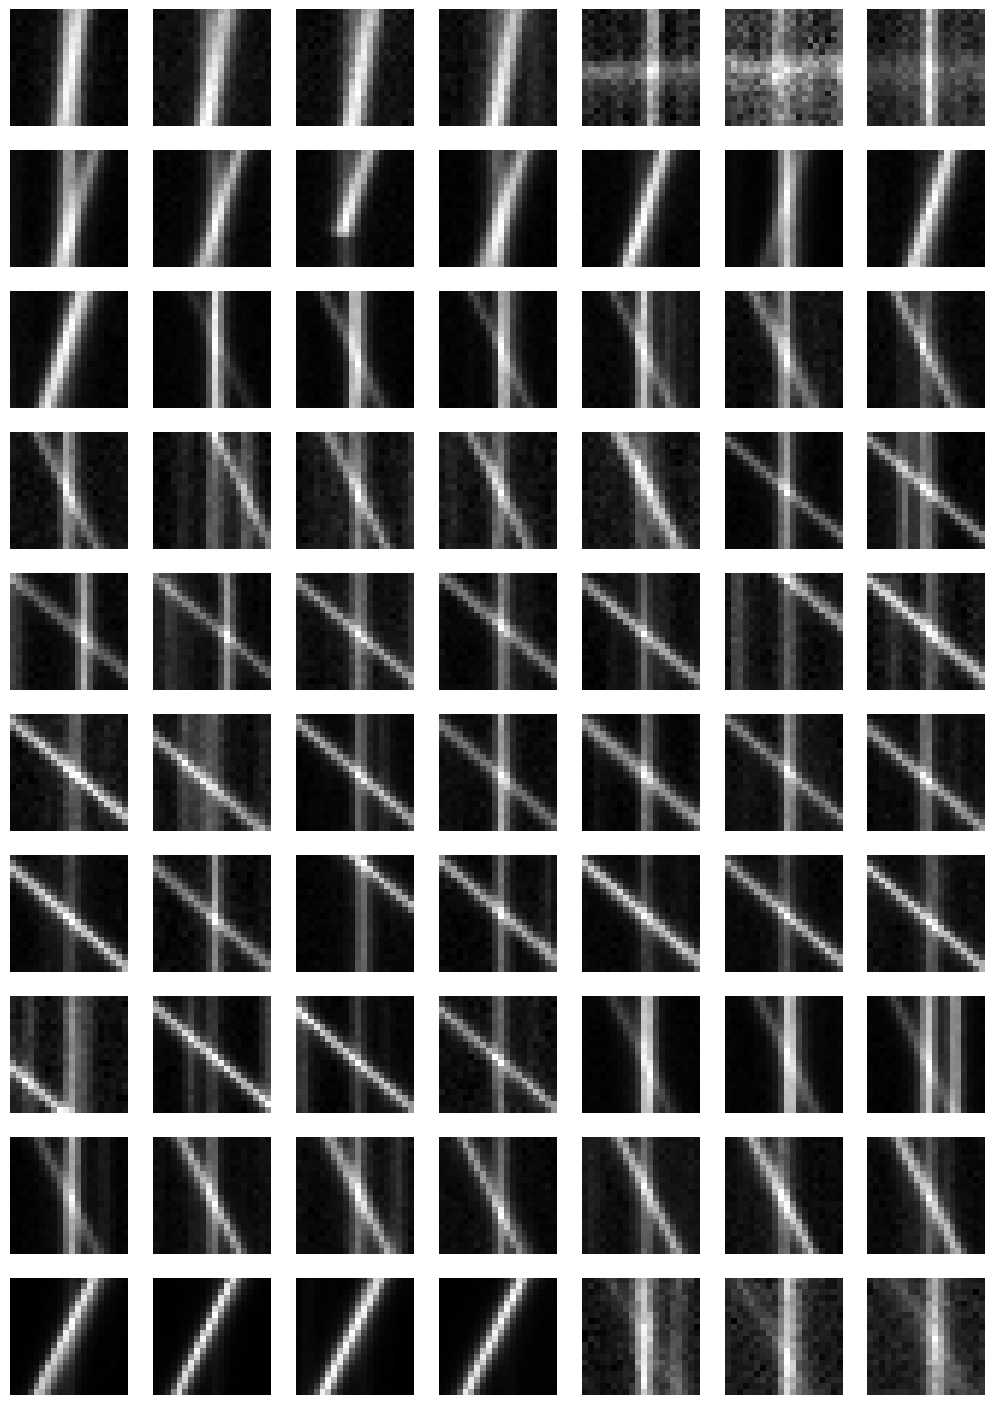

In [34]:
centered = loaded[(loaded_info[:,4]=='0') & (loaded_info[:,5]=='0')]
figcols = 7
figrows = 10
fig, ax = plt.subplots(figrows, figcols, figsize=(figcols * 1.8, figrows * 1.8))
for i in range(figrows):
    for j in range(figcols):
        index = figcols * i + j
        ax[i, j].imshow(centered[index])
        ax[i, j].set_axis_off()
        
            
# for i in range(len(loaded_info)):
#     if loaded_info[i][4]=='0' and loaded_info[i][5]=='0':
#         plt.imshow(loaded[i])
#         plt.show()

In [39]:
fpath_sat = "/lustre/lrspec/ZTF_data/training_feb26/stamps_satellites/"

image_path = fpath_sat + "images/"
info_path = fpath_sat + "info/"
for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
        # Add file index as first column
    # file_idx = np.full((infos_arr.shape[0], 1), i)
    # infos_arr = np.concatenate([file_idx, infos_arr], axis=1)
    file_idx = np.arange(0, len(infos_arr))
    infos_arr[:,0]=file_idx
    
    print(np.shape(trans))
    print(np.shape(infos))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_sat_stamps = trans_arr
        all_sat_stamps_info = infos_arr
    else:
        all_sat_stamps = np.concatenate((all_sat_stamps, trans_arr), axis=0)
        all_sat_stamps_info = np.concatenate((all_sat_stamps_info, infos_arr), axis=0)

        

sat_stamps.npy
(25460, 20, 20)
(25460, 6)


array([    0,     1,     2, ..., 25457, 25458, 25459])

In [42]:
all_sat_stamps_info.astype('int')

array([[    0,     4,   154,  2479,    -9,    -9],
       [    1,     4,   154,  2479,    -9,    -8],
       [    2,     4,   154,  2479,    -9,    -7],
       ...,
       [25457,     4,  1338,  1553,     9,     7],
       [25458,     4,  1338,  1553,     9,     8],
       [25459,     4,  1338,  1553,     9,     9]])

In [30]:
all_streak_stamps_info[14]

array([   0,    0,    0, 1113, 1357,   -2])

In [23]:





fpath_streak = "/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_streaks/"


# for i, file in enumerate(os.listdir(fpath_streak)):
#     image_filename = os.fsdecode(file)
#     image_filename_full = fpath_streak + image_filename
#     print(image_filename)
#     streak = np.load(image_filename_full)
#     streak_arr = np.array(streak)
#     print(np.shape(streak))
#     # all_trans_stamps.append(trans_arr)
#     if i == 0:
#         all_streak_stamps = streak_arr
#     else:
#         all_streak_stamps = np.concatenate((all_streak_stamps, streak_arr), axis=0)

image_path = fpath_streak + "images/"
info_path = fpath_streak + "info/"

for i, file in enumerate(os.listdir(image_path)):
    if i<10:
        image_filename = os.fsdecode(file)
        image_filename_full = image_path + image_filename
        print(image_filename)
        info_filename = image_filename[:-4] + "_info.npy"
        info_filename_full = info_path + info_filename
        trans = np.load(image_filename_full)
        trans_arr = np.array(trans)
        infos = np.load(info_filename_full)
        infos_arr = np.array(infos)
            # Add file index as first column
        file_idx = np.full((infos_arr.shape[0], 1), i)
        infos_arr = np.concatenate([file_idx, infos_arr], axis=1)
    
        print(np.shape(trans))
        print(np.shape(infos))
        # all_trans_stamps.append(trans_arr)
        if i == 0:
            all_streak_stamps = trans_arr
            all_streak_stamps_info = infos_arr
        else:
            all_streak_stamps = np.concatenate((all_streak_stamps, trans_arr), axis=0)
            all_streak_stamps_info = np.concatenate((all_streak_stamps_info, infos_arr), axis=0)



ztf_20220820237546_000798_zr_c06_x_0000._4_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802_zg_c03_x_0006._3_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20220820237546_000798_zr_c13_x_0002._2_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221017148750_000831_zi_c04_x_0007._1_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221020138241_000686_zi_c06_x_0003._4_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20220820237546_000798_zr_c14_x_0000._2_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221020138241_000686_zi_c05_x_0007._3_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802_zg_c01_x_0025._1_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221017148750_000831_zi_c03_x_0005._1_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221020138241_000686_zi_c01_x_0001._4_stamps.npy
(50, 20, 20)
(50, 5)
